<a href="https://colab.research.google.com/github/rraidero/ifes-mestrado/blob/main/Laborat%C3%B3rio_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto de Forecasting: Competição Playground Series S6E10

```
Rodrigo Raider de Oliveira
```

Este notebook apresenta o desenvolvimento de modelos de previsão (forecasting) utilizando os dados da competição do Kaggle.

https://www.kaggle.com/competitions/playground-series-s6e10

---



## 1. Descrição e Explicação da Base de Dados

Este laboratório utiliza o conjunto de dados da competição Airline Passenger Satisfaction, disponibilizado no Kaggle, que reúne informações sobre passageiros, características de suas viagens e avaliações de serviços de companhias aéreas. O objetivo é desenvolver modelos capazes de classificar a satisfação dos passageiros em duas categorias: satisfeitos e insatisfeitos.

Inicialmente, será estabelecida uma baseline ingênua (Naïve), que prevê sempre a classe majoritária do conjunto de treinamento, servindo como referência para avaliar o desempenho dos modelos. Em seguida, serão implementadas e comparadas quatro arquiteturas de redes neurais: Densely Connected, Convolutional Neural Network 1D (CNN 1D), Long Short-Term Memory (LSTM) e Bidirectional LSTM (BiLSTM).

O pré-processamento inclui a codificação das variáveis categóricas por One-Hot Encoding, a padronização das variáveis numéricas e a separação dos dados em conjuntos de treinamento e validação. Os modelos serão avaliados por métricas como acurácia e erro absoluto médio (MAE) das probabilidades previstas, permitindo comparar seu desempenho e sua capacidade de generalização.

Embora as arquiteturas recorrentes e convolucionais sejam frequentemente aplicadas a dados sequenciais, neste laboratório elas serão adaptadas a um problema de classificação tabular. Essa escolha será considerada na interpretação dos resultados, especialmente ao comparar essas arquiteturas com a rede densamente conectada.


In [26]:
# Instalação do pacote oficial do Kaggle para download automatizado de datasets
!pip install -q kaggle

# Interface para upload do arquivo de credenciais 'kaggle.json' gerado na conta do usuário
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (2).json


{'kaggle (2).json': b'{"username":"rodrigoolive","key":"ae60df480f8f6c2eebd46857e300aecc"}'}

In [27]:
# Configuração do diretório local de credenciais do Kaggle e definição de permissões de segurança
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [28]:
# Download dos dados compactados da competição diretamente da plataforma Kaggle
!kaggle competitions download -c playground-series-s6e10

# Extração dos arquivos CSV (treino, teste e modelo de submissão)
!unzip -o playground-series-s6e10.zip

playground-series-s6e10.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  playground-series-s6e10.zip
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [29]:
# Importação da biblioteca pandas e carregamento inicial dos arquivos de treino e teste em DataFrames
import pandas as pd

# Carregando os datasets nas variáveis correspondentes
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

print(f"Dataset de Treino: {df_train.shape[0]} linhas e {df_train.shape[1]} colunas.")
print(f"Dataset de Teste: {df_test.shape[0]} linhas e {df_test.shape[1]} colunas.")

Dataset de Treino: 699635 linhas e 23 colunas.
Dataset de Teste: 299844 linhas e 22 colunas.


In [30]:
# Visualização das primeiras 5 linhas do dataset para entender a disposição física e o conteúdo das colunas
display(df_train.head())

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [31]:
# Inspeção estrutural do dataset de treino: verificação de tipos das colunas, contagem de registros preenchidos e espaço em memória
print("=== Informações do Dataset de Treino ===")
df_train.info()

=== Informações do Dataset de Treino ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11

In [32]:
# Geração do resumo estatístico (média, desvio padrão, mínimos, máximos e quartis) para todas as variáveis numéricas
print("=== Estatísticas Descritivas ===")
display(df_train.describe())

=== Estatísticas Descritivas ===


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.000000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.000000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.372129,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.000000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.500000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.000000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.500000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


## 2. Preparação do Dataset e Justificativa de Parâmetros


### Divisão de Treino e Validação (80/20)

Foi utilizada a função `train_test_split`, com 80% dos dados destinados ao treinamento e 20% à validação, além de `random_state=42` para garantir a reprodutibilidade. O parâmetro `stratify=y` preserva aproximadamente a proporção original das classes nos dois conjuntos, reduzindo o risco de avaliações distorcidas pela distribuição dos rótulos.

### Seleção e Pré-processamento das Variáveis

A coluna `id` foi removida por representar um identificador, sem significado preditivo diretamente estabelecido. As variáveis numéricas foram tratadas com imputação pela mediana e padronização, enquanto as categóricas receberam imputação pela categoria mais frequente e codificação *One-Hot Encoding*. O parâmetro `handle_unknown='ignore'` permite processar categorias não observadas durante o treinamento.

O pré-processamento foi ajustado exclusivamente com os dados de treinamento e aplicado posteriormente à validação, evitando o vazamento de informações entre os conjuntos.

### Adaptação às Arquiteturas Neurais

Para a rede densamente conectada (MLP), os dados foram mantidos no formato tabular bidimensional. Já para a CNN 1D, a LSTM e a BiLSTM, foi adicionada uma dimensão de canal, convertendo os dados para o formato tridimensional esperado por essas arquiteturas.

Essa adaptação permite executar os modelos convolucionais e recorrentes, mas os atributos são tratados como uma sequência artificial, pois não representam observações ordenadas no tempo. Essa limitação deve ser considerada na interpretação e comparação dos resultados.

In [33]:
from sklearn.model_selection import train_test_split

# Definir a variável-alvo
target = 'satisfaction'

# Separar as variáveis preditoras e a variável-alvo
X = df_train.drop(columns=[target, 'id'])
y = df_train[target]

# Separar treino e validação
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Exibir as dimensões dos conjuntos
print("Dimensões dos conjuntos:")
print(f"Treino:    X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Validação: X_val   = {X_val.shape}, y_val   = {y_val.shape}")

# Verificar a distribuição da variável-alvo
print("\nDistribuição da variável-alvo:")
print("Original:")
print(y.value_counts(normalize=True))

print("\nTreino:")
print(y_train.value_counts(normalize=True))

print("\nValidação:")
print(y_val.value_counts(normalize=True))

Dimensões dos conjuntos:
Treino:    X_train = (559708, 21), y_train = (559708,)
Validação: X_val   = (139927, 21), y_val   = (139927,)

Distribuição da variável-alvo:
Original:
satisfaction
False    0.556427
True     0.443573
Name: proportion, dtype: float64

Treino:
satisfaction
False    0.556428
True     0.443572
Name: proportion, dtype: float64

Validação:
satisfaction
False    0.556426
True     0.443574
Name: proportion, dtype: float64


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais
sns.set_theme(style="whitegrid")

# Identificar variável-alvo
target = 'satisfaction'

# Separar variáveis numéricas e categóricas
numeric_cols = df_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Linhas: {df_train.shape[0]}")
print(f"Colunas: {df_train.shape[1]}")
print(f"Variáveis numéricas: {len(numeric_cols)}")
print(f"Variáveis categóricas: {len(categorical_cols)}")

print("\nColunas numéricas:")
print(numeric_cols)

print("\nColunas categóricas:")
print(categorical_cols)

Linhas: 699635
Colunas: 23
Variáveis numéricas: 18
Variáveis categóricas: 4

Colunas numéricas:
['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

Colunas categóricas:
['Gender', 'Customer Type', 'Type of Travel', 'Class']


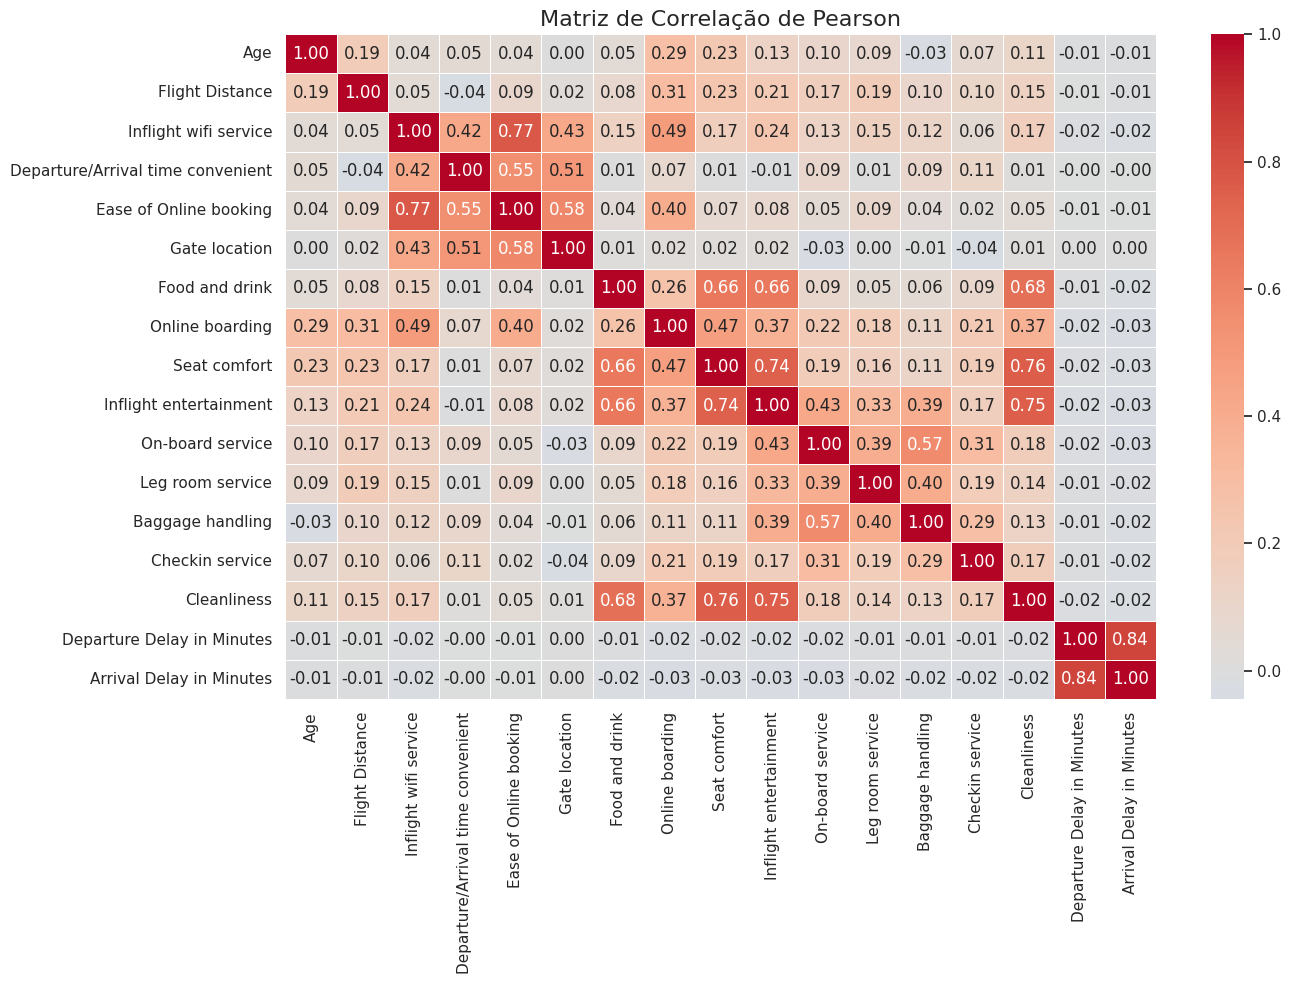

In [35]:
# Criar cópia com a variável-alvo codificada numericamente
df_corr = df_train.copy()

# Codificar a variável-alvo como 0 e 1
if df_corr[target].dtype == 'object':
    df_corr[target] = df_corr[target].map({
        'dissatisfied': 0,
        'satisfied': 1
    })

# Selecionar apenas colunas numéricas
df_corr_numeric = df_corr.select_dtypes(include=np.number)

# Excluir identificadores, pois não representam medidas
df_corr_numeric = df_corr_numeric.drop(
    columns=['id'],
    errors='ignore'
)

# Calcular a matriz de correlação
corr_matrix = df_corr_numeric.corr()

# Plotar a matriz
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Matriz de Correlação de Pearson', fontsize=16)
plt.tight_layout()
plt.show()

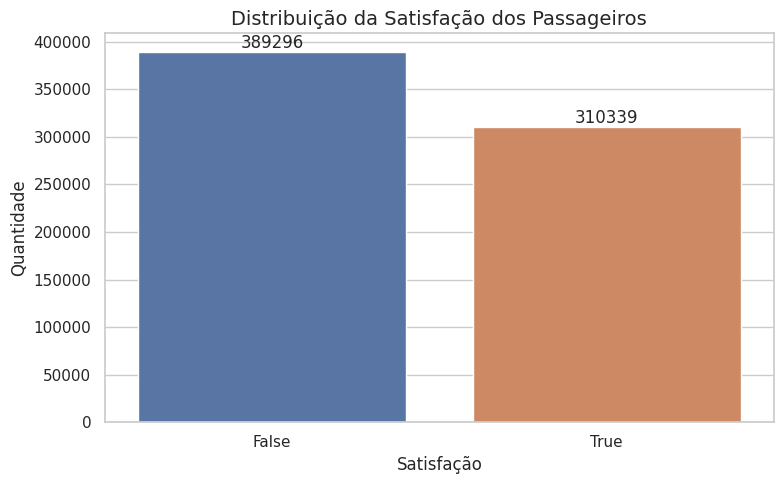


Proporção das classes:
satisfaction
False    55.64%
True     44.36%
Name: proportion, dtype: object


In [36]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_train,
    x=target,
    hue=target,
    legend=False
)

plt.title('Distribuição da Satisfação dos Passageiros', fontsize=14)
plt.xlabel('Satisfação')
plt.ylabel('Quantidade')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

print("\nProporção das classes:")
print(
    df_train[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str) + '%'
)

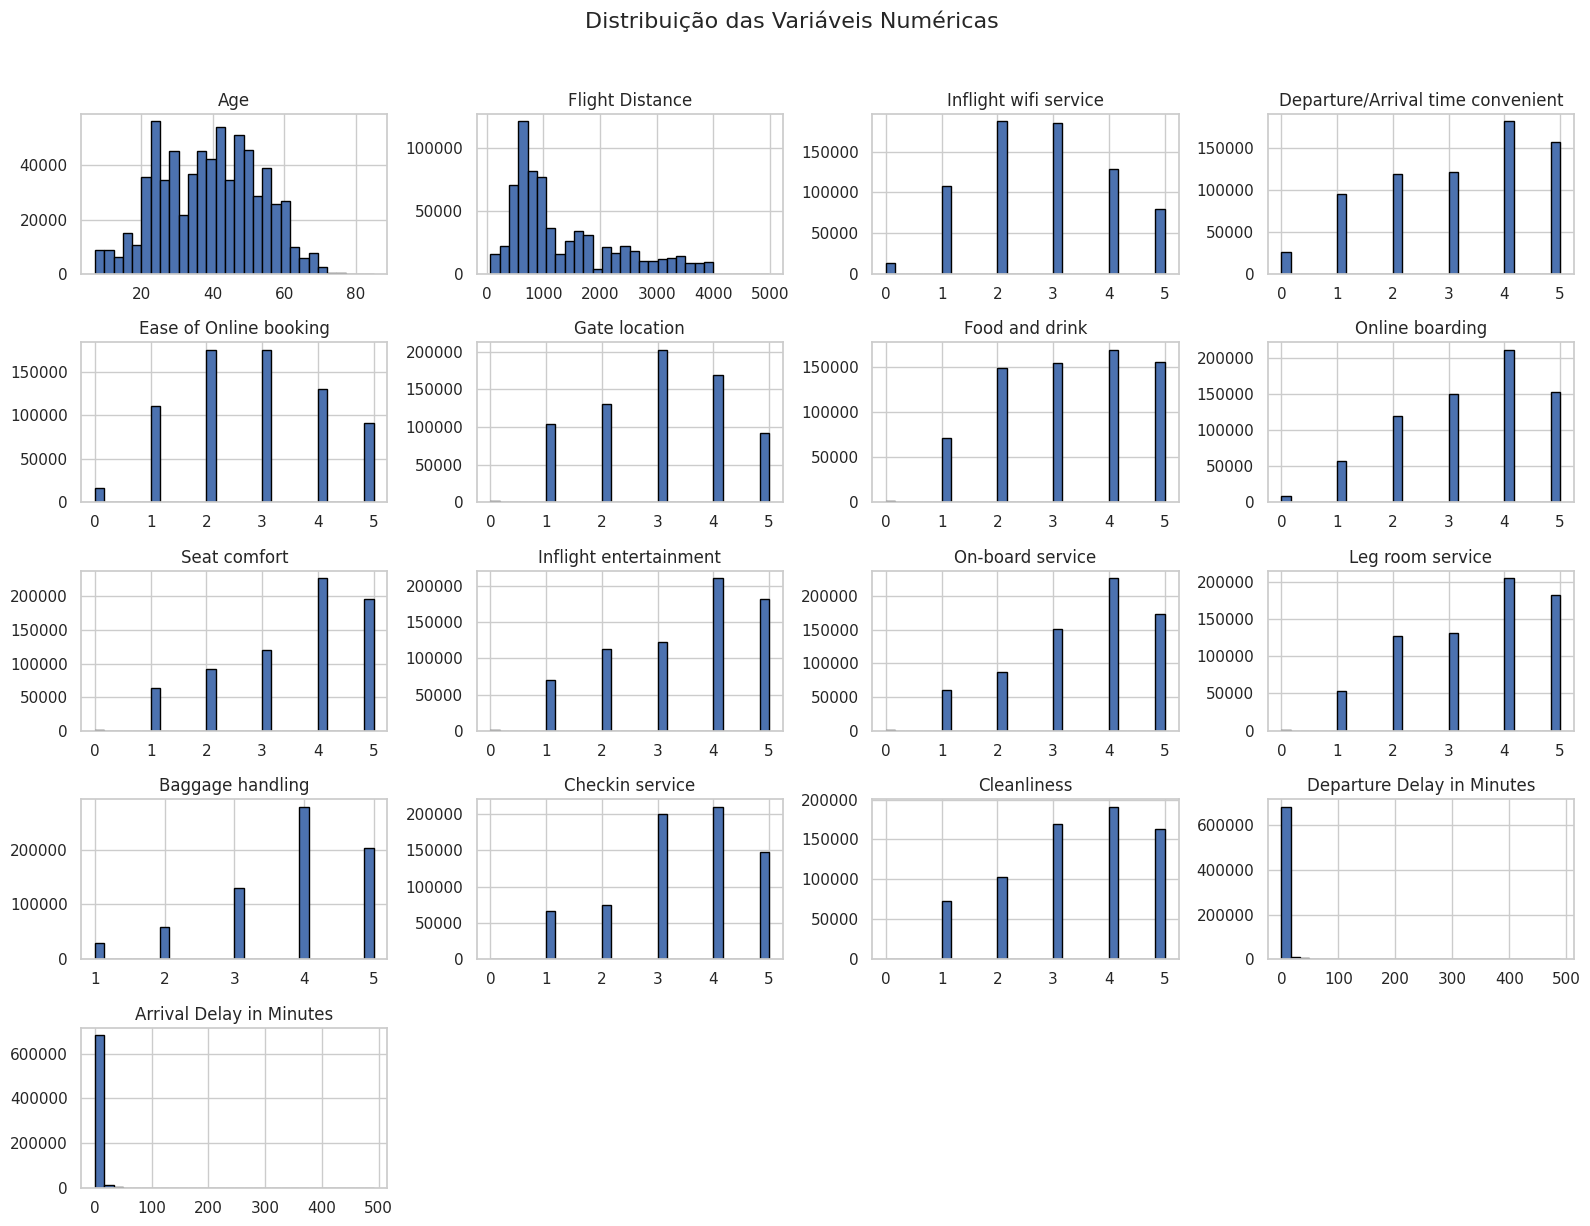

In [37]:
# Remover identificadores dos gráficos
numeric_plot_cols = [
    col for col in numeric_cols
    if col != 'id'
]

df_train[numeric_plot_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distribuição das Variáveis Numéricas',
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

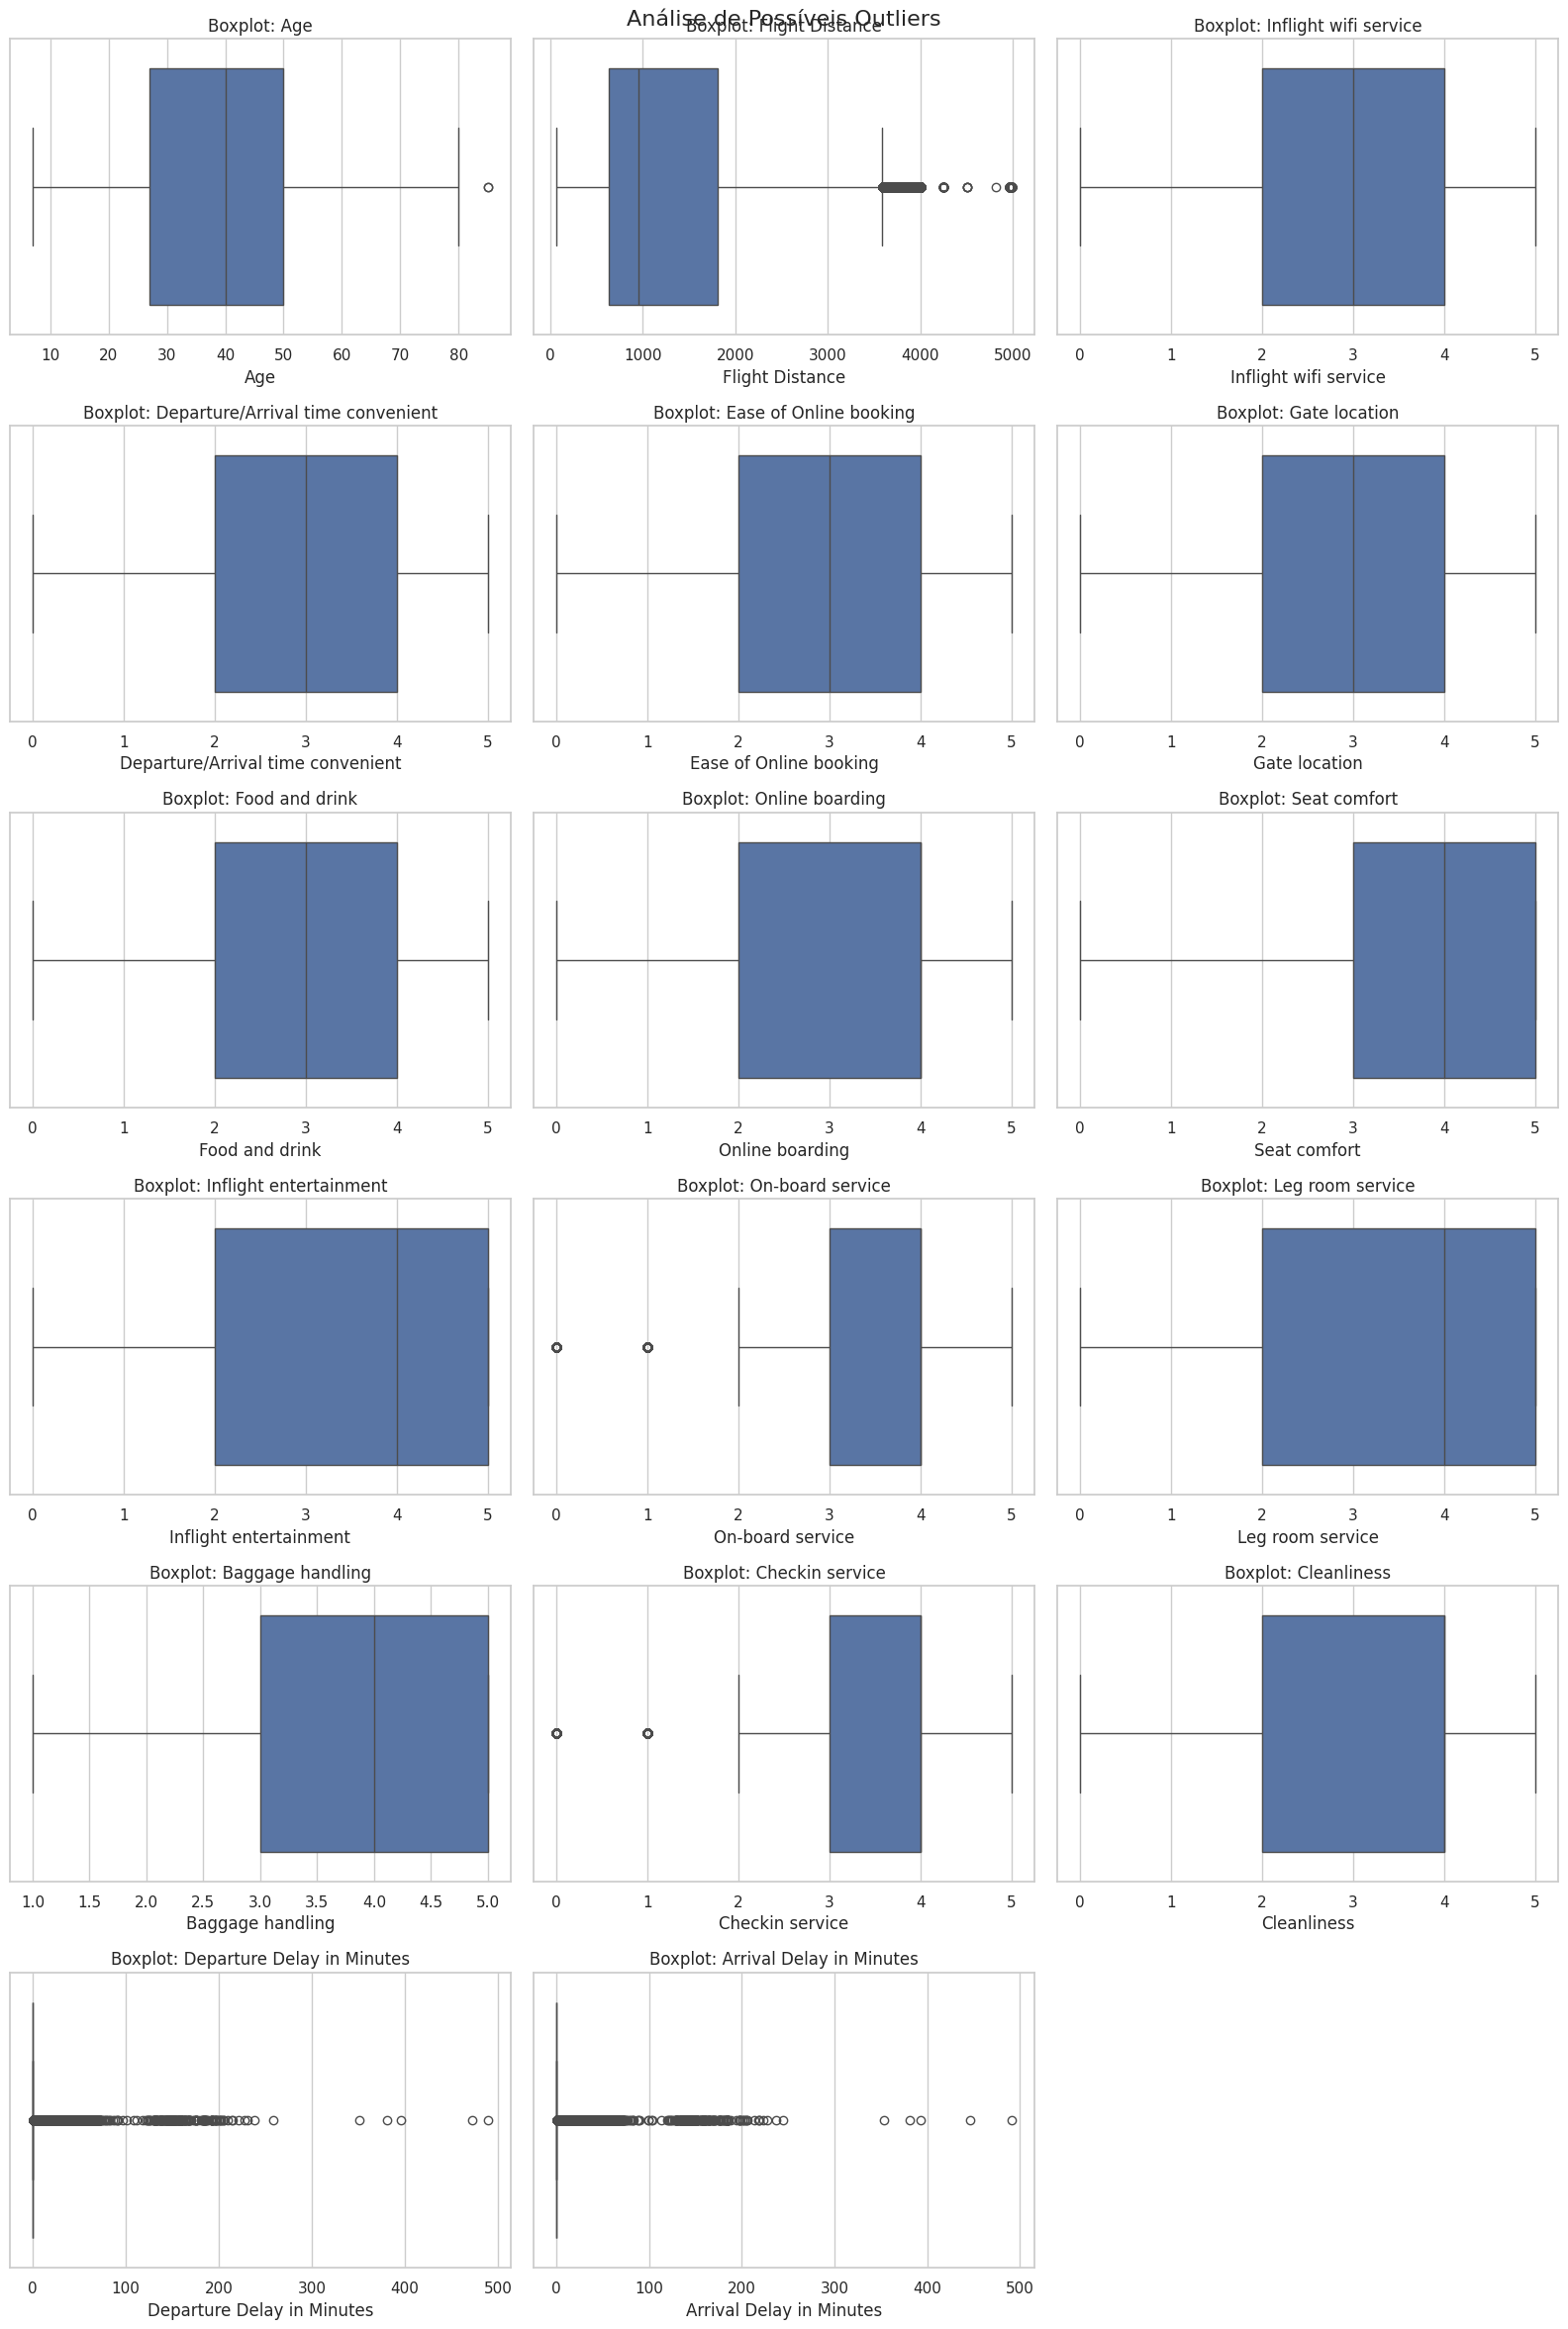

In [38]:
numeric_box_cols = [
    col for col in numeric_plot_cols
    if df_train[col].nunique() > 2
]

n_cols = 3
n_rows = int(np.ceil(len(numeric_box_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

axes = np.array(axes).reshape(-1)

for i, col in enumerate(numeric_box_cols):
    sns.boxplot(
        data=df_train,
        x=col,
        ax=axes[i]
    )
    axes[i].set_title(f'Boxplot: {col}')

for i in range(len(numeric_box_cols), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Análise de Possíveis Outliers', fontsize=16)
plt.tight_layout()
plt.show()

In [39]:
missing = pd.DataFrame({
    'Valores ausentes': df_train.isnull().sum(),
    'Percentual (%)': (
        df_train.isnull().mean() * 100
    ).round(2)
})

missing = missing.sort_values(
    'Percentual (%)',
    ascending=False
)

display(missing[missing['Valores ausentes'] > 0])

if df_train.isnull().sum().sum() == 0:
    print("Não foram encontrados valores ausentes no conjunto de treino.")

,Valores ausentes,Percentual (%)
Arrival Delay in Minutes,292,0.04


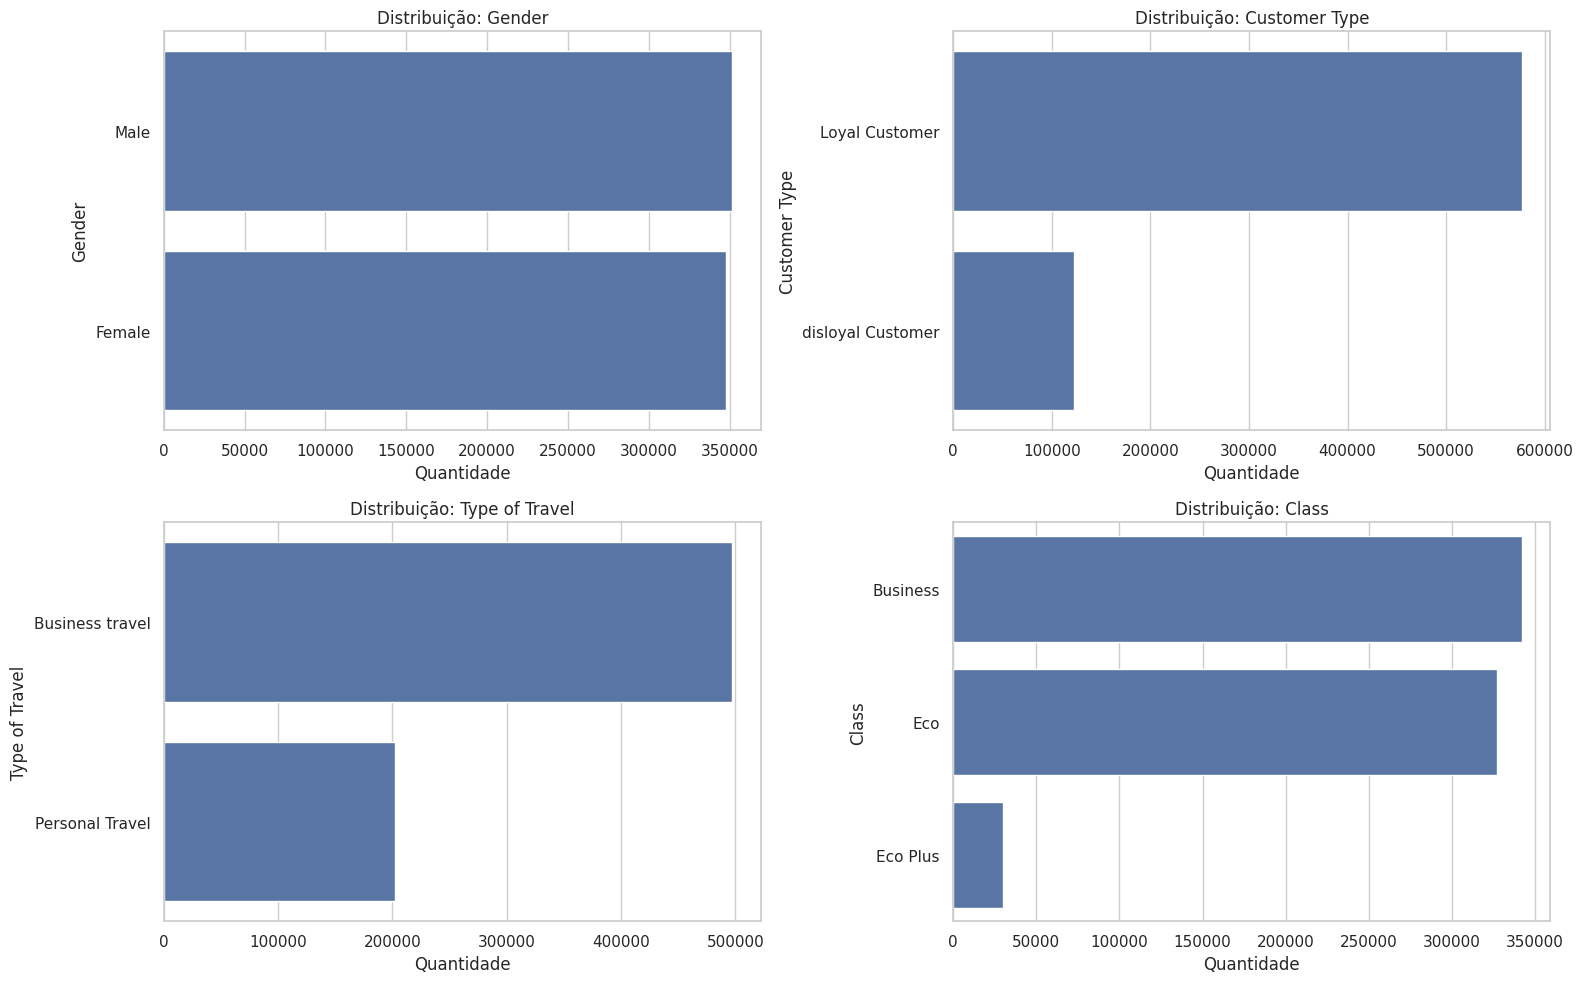

In [40]:
categorical_plot_cols = [
    col for col in categorical_cols
    if col != target
]

n_cols = 2
n_rows = int(np.ceil(len(categorical_plot_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 5 * n_rows)
)

axes = np.array(axes).reshape(-1)

for i, col in enumerate(categorical_plot_cols):
    order = df_train[col].value_counts().index

    sns.countplot(
        data=df_train,
        y=col,
        order=order,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribuição: {col}')
    axes[i].set_xlabel('Quantidade')
    axes[i].set_ylabel(col)

for i in range(len(categorical_plot_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

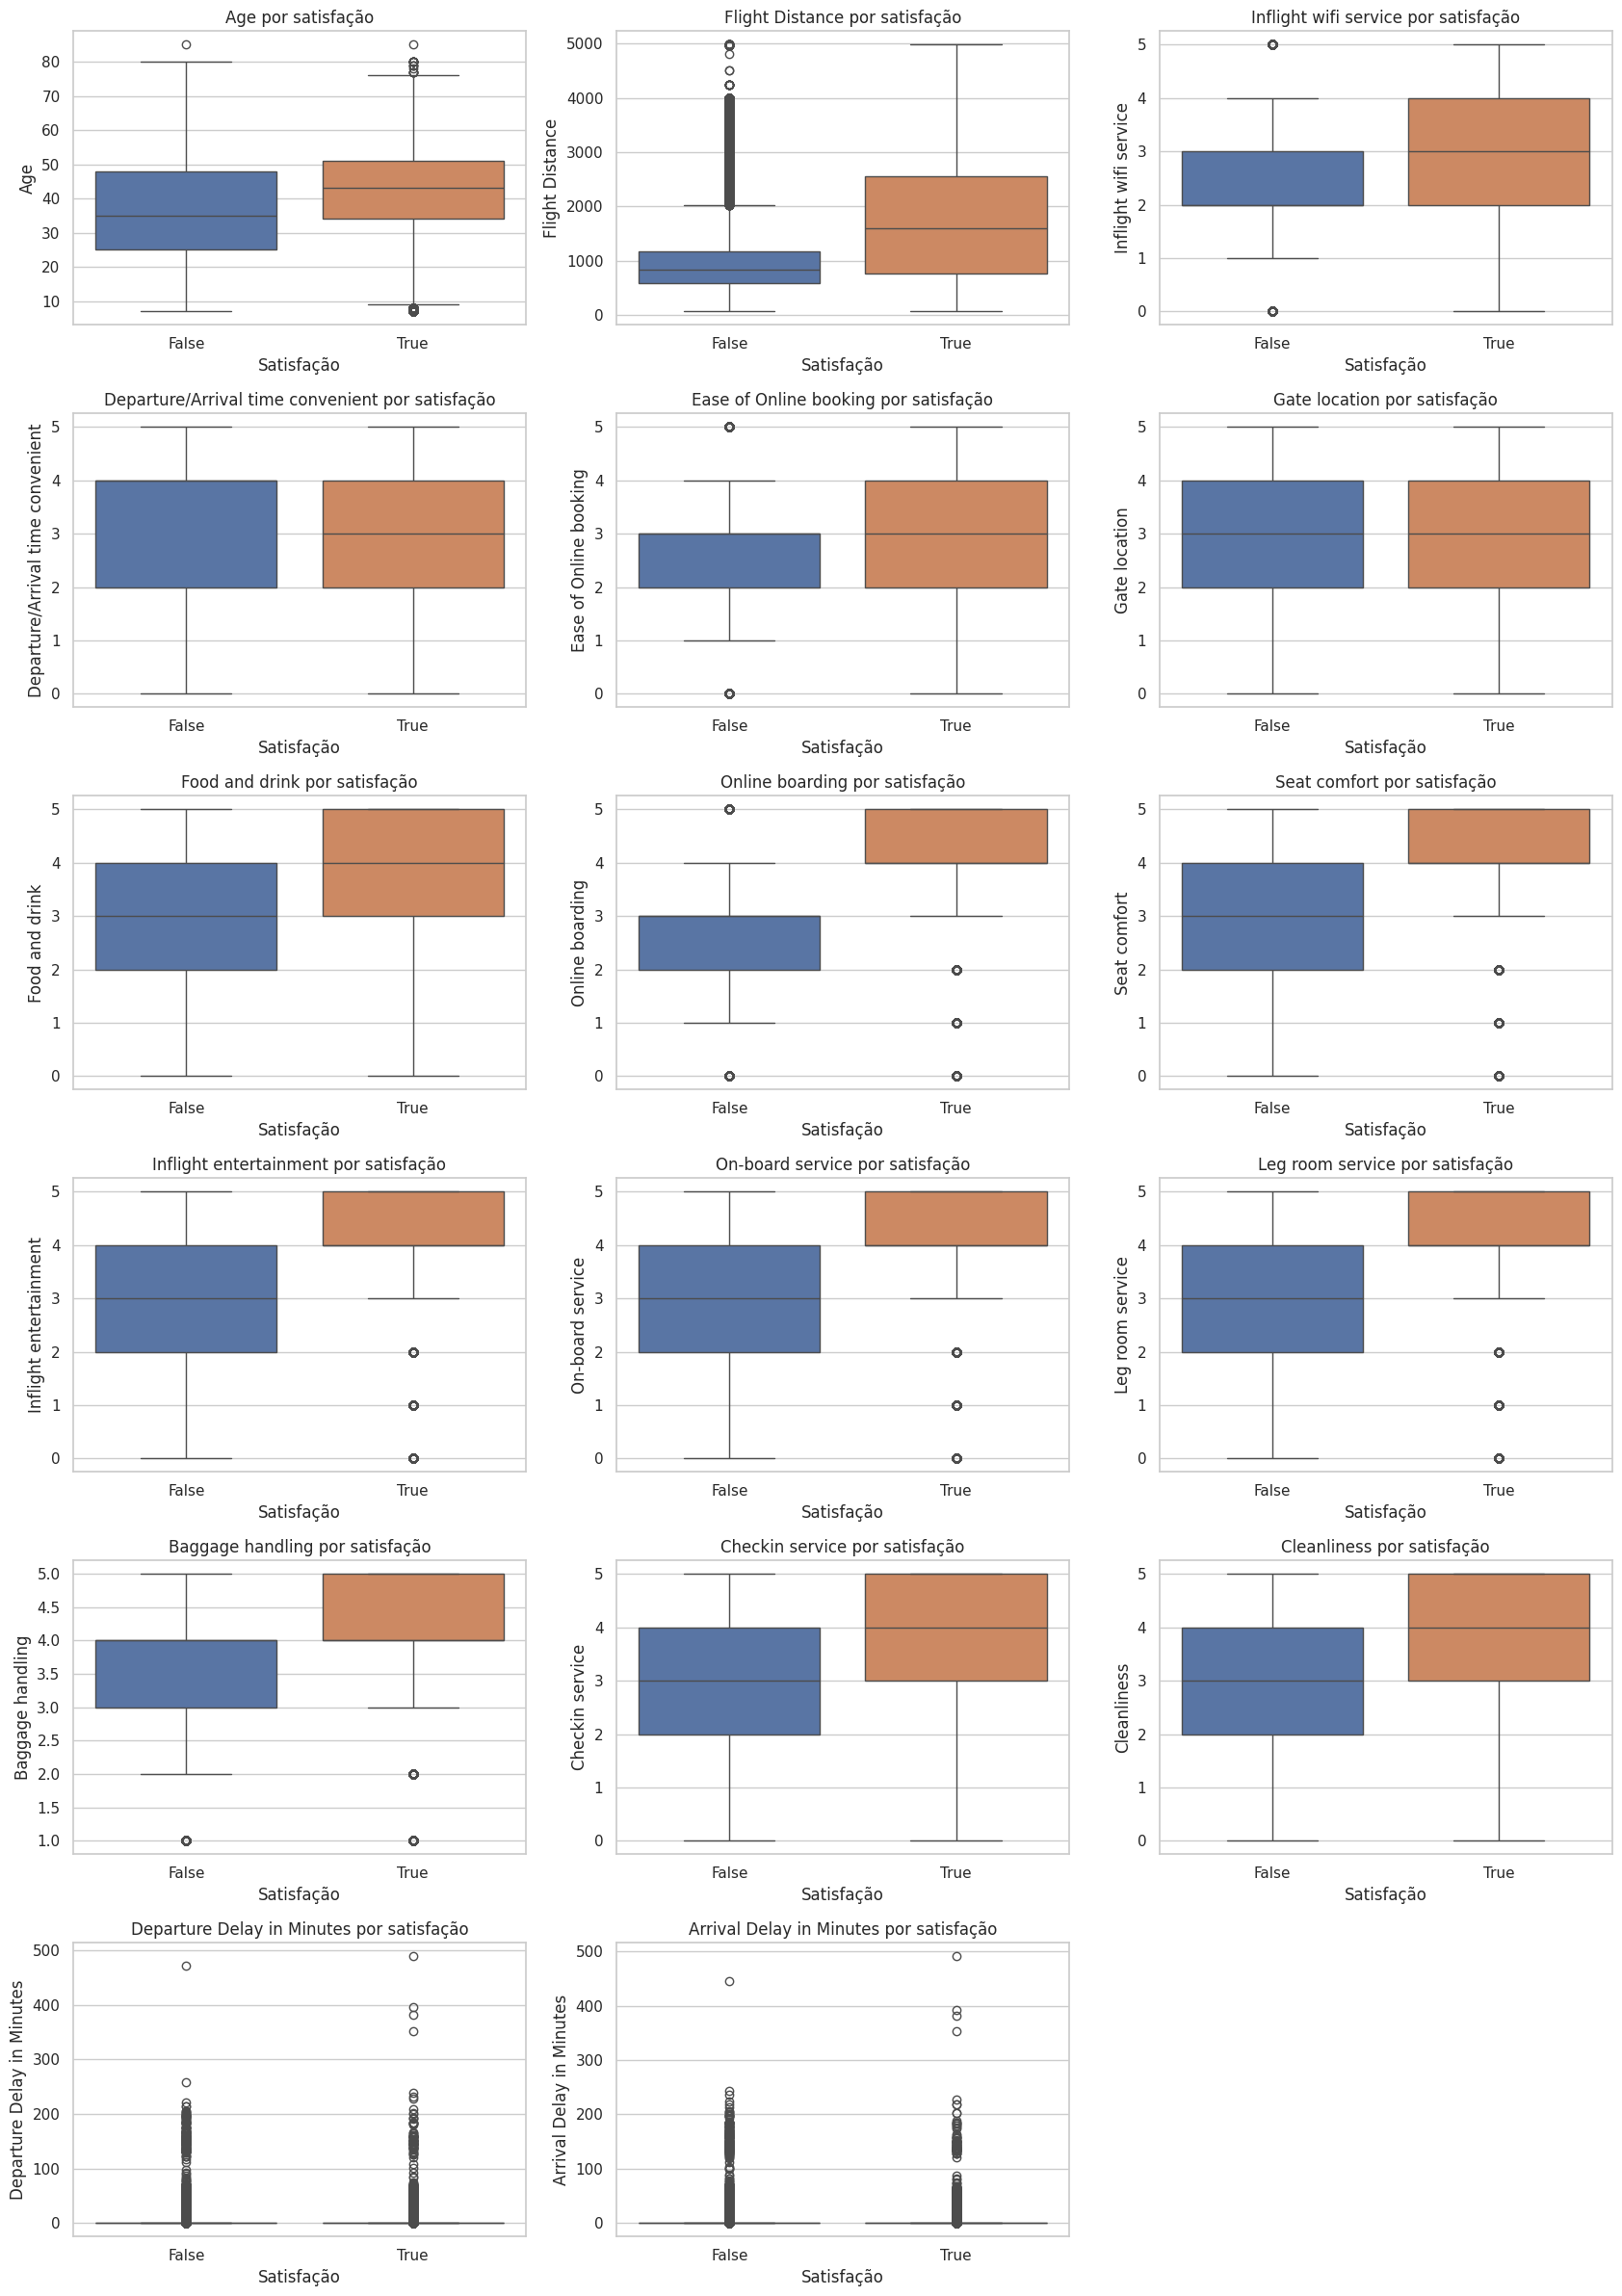

In [41]:
# Excluir identificadores e variáveis com apenas uma categoria
features_for_comparison = [
    col for col in numeric_plot_cols
    if df_train[col].nunique() > 2
]

n_cols = 3
n_rows = int(np.ceil(len(features_for_comparison) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(17, 4 * n_rows)
)

axes = np.array(axes).reshape(-1)

for i, col in enumerate(features_for_comparison):
    sns.boxplot(
        data=df_train,
        x=target,
        y=col,
        hue=target,
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} por satisfação')
    axes[i].set_xlabel('Satisfação')
    axes[i].set_ylabel(col)

for i in range(len(features_for_comparison), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identificar variáveis numéricas e categóricas
numeric_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Variáveis numéricas:", numeric_features)
print("Variáveis categóricas:", categorical_features)

# Pré-processamento das variáveis categóricas
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Pré-processamento das variáveis numéricas
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Combinar os tratamentos
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Ajustar apenas com os dados de treino
X_train_encoded = preprocessor.fit_transform(X_train)

# Aplicar a mesma transformação à validação
X_val_encoded = preprocessor.transform(X_val)

print("\nDimensões após o encoding:")
print("Treino:", X_train_encoded.shape)
print("Validação:", X_val_encoded.shape)

Variáveis numéricas: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Variáveis categóricas: ['Gender', 'Customer Type', 'Type of Travel', 'Class']

Dimensões após o encoding:
Treino: (559708, 26)
Validação: (139927, 26)


## 3. Modelo Baseline (Naïve Approach)

In [43]:
import numpy as np
from sklearn.metrics import mean_absolute_error, accuracy_score

# Identificar a classe majoritária exclusivamente no treino
naive_class = y_train.mode()[0]

# Gerar previsões para validação
y_val_naive = np.full(
    shape=len(y_val),
    fill_value=naive_class
)

# Avaliar a baseline
mae = mean_absolute_error(
    y_val,
    y_val_naive
)

accuracy = accuracy_score(
    y_val,
    y_val_naive
)

print(f"Classe prevista pela baseline: {naive_class}")
print(f"Validation MAE: {mae:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

Classe prevista pela baseline: False
Validation MAE: 0.4436
Validation Accuracy: 0.5564


A baseline implementada consiste em prever sempre a classe majoritária do conjunto de treinamento, resultando em uma acurácia de 55,64% e um MAE de 0,4436 no conjunto de validação. Esse resultado reflete a limitação do método, que não considera as características individuais dos passageiros para estimar sua satisfação, utilizando apenas a frequência das classes como referência. Portanto, as métricas obtidas estabelecem um ponto de comparação para avaliar se os modelos subsequentes conseguem identificar padrões relevantes nos dados e melhorar o desempenho preditivo. Cabe ressaltar que essa abordagem é uma baseline de classificação, e não o método Naïve convencional de forecasting, que utiliza a última observação de uma série temporal como previsão para o período seguinte.

## 4. Técnicas Avançadas de Forecasting

In [44]:
import numpy as np
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Converter os rótulos para 0 e 1
y_train_nn = y_train.astype(np.float32).to_numpy()
y_val_nn = y_val.astype(np.float32).to_numpy()

# Converter os dados para arrays densos, caso sejam matrizes esparsas
if hasattr(X_train_encoded, "toarray"):
    X_train_nn = X_train_encoded.toarray()
    X_val_nn = X_val_encoded.toarray()
else:
    X_train_nn = np.asarray(X_train_encoded)
    X_val_nn = np.asarray(X_val_encoded)

# Garantir o tipo numérico adequado
X_train_nn = X_train_nn.astype(np.float32)
X_val_nn = X_val_nn.astype(np.float32)

print("Formato do treino:", X_train_nn.shape)
print("Formato da validação:", X_val_nn.shape)
print("Formato dos rótulos:", y_train_nn.shape)

Formato do treino: (559708, 26)
Formato da validação: (139927, 26)
Formato dos rótulos: (559708,)


In [45]:
# Garantir reprodutibilidade
tf.keras.utils.set_random_seed(42)

# Criar o modelo
model = keras.Sequential([
    layers.Input(shape=(X_train_nn.shape[1],)),

    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),

    layers.Dense(1, activation='sigmoid')
])

# Configurar o treinamento
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Exibir a arquitetura
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7797 - loss: 0.7008 - val_accuracy: 0.8104 - val_loss: 0.5509
Epoch 2/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8343 - loss: 0.4604 - val_accuracy: 0.8742 - val_loss: 0.3581
Epoch 3/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8508 - loss: 0.4199 - val_accuracy: 0.8872 - val_loss: 0.3261
Epoch 4/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8633 - loss: 0.3889 - val_accuracy: 0.8939 - val_loss: 0.3092
Epoch 5/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8704 - loss: 0.3700 - val_accuracy: 0.8805 - val_loss: 0.3408
Epoch 6/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8780 - loss: 0.3457 - val_accuracy: 0.7705 - val_loss: 0.5062
Epoch 7/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8809 - loss: 0.3367 - val_accuracy: 0.8869 - val_loss: 0.3234
Epoch 8/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8850 - loss: 0.3271 - 

In [47]:
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix
)

# Obter probabilidades previstas
y_val_prob = model.predict(
    X_val_nn,
    verbose=0
).ravel()

# Converter probabilidades em classes
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Avaliar
accuracy = accuracy_score(y_val_nn, y_val_pred)

mae = mean_absolute_error(
    y_val_nn,
    y_val_prob
)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation MAE probabilístico: {mae:.4f}")

print("\nRelatório de classificação:")
print(
    classification_report(
        y_val_nn.astype(int),
        y_val_pred,
        target_names=['Dissatisfied', 'Satisfied']
    )
)

print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_val_nn.astype(int),
        y_val_pred
    )
)

Validation Accuracy: 0.9125
Validation MAE probabilístico: 0.1441

Relatório de classificação:
              precision    recall  f1-score   support

Dissatisfied       0.91      0.94      0.92     77859
   Satisfied       0.92      0.88      0.90     62068

    accuracy                           0.91    139927
   macro avg       0.91      0.91      0.91    139927
weighted avg       0.91      0.91      0.91    139927


Matriz de confusão:
[[73012  4847]
 [ 7401 54667]]


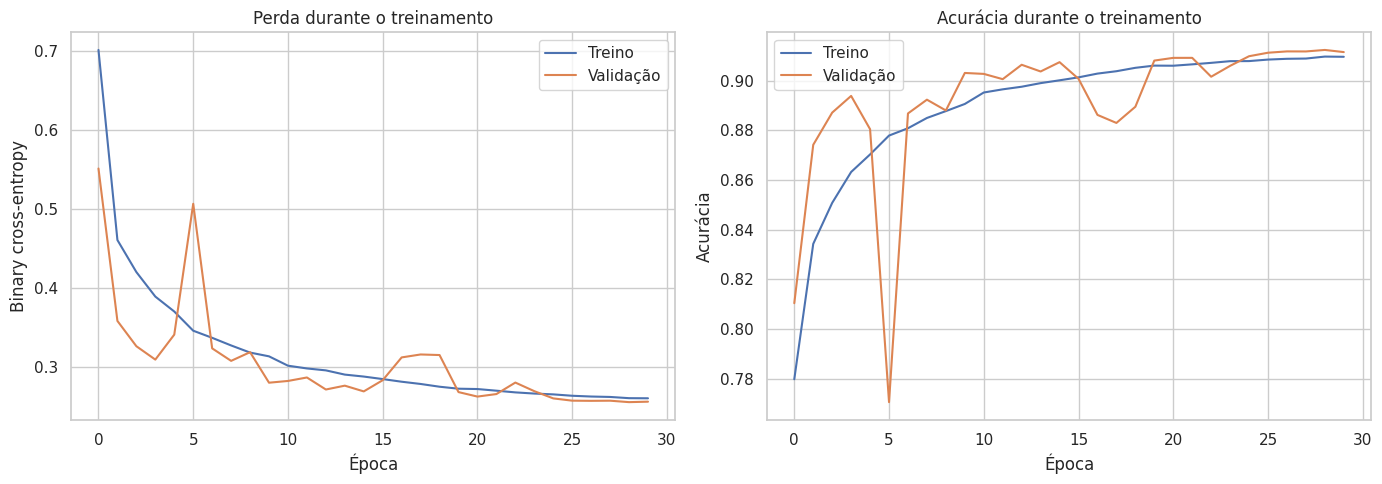

In [48]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Perda
axes[0].plot(history.history['loss'], label='Treino')
axes[0].plot(history.history['val_loss'], label='Validação')
axes[0].set_title('Perda durante o treinamento')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Binary cross-entropy')
axes[0].legend()

# Acurácia
axes[1].plot(history.history['accuracy'], label='Treino')
axes[1].plot(history.history['val_accuracy'], label='Validação')
axes[1].set_title('Acurácia durante o treinamento')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Acurácia')
axes[1].legend()

plt.tight_layout()
plt.show()

In [49]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix
)

# Converter os dados para arrays densos, caso sejam matrizes esparsas
if hasattr(X_train_encoded, "toarray"):
    X_train_cnn = X_train_encoded.toarray()
    X_val_cnn = X_val_encoded.toarray()
else:
    X_train_cnn = np.asarray(X_train_encoded)
    X_val_cnn = np.asarray(X_val_encoded)

# Garantir tipo numérico
X_train_cnn = X_train_cnn.astype(np.float32)
X_val_cnn = X_val_cnn.astype(np.float32)

# Converter os rótulos para 0 e 1
y_train_cnn = y_train.astype(np.float32).to_numpy()
y_val_cnn = y_val.astype(np.float32).to_numpy()

# Adicionar a dimensão de canal
X_train_cnn = X_train_cnn[..., np.newaxis]
X_val_cnn = X_val_cnn[..., np.newaxis]

print("Formato do treino:", X_train_cnn.shape)
print("Formato da validação:", X_val_cnn.shape)

Formato do treino: (559708, 26, 1)
Formato da validação: (139927, 26, 1)


In [50]:
# Garantir reprodutibilidade
tf.keras.utils.set_random_seed(42)

model_cnn = keras.Sequential([
    layers.Input(shape=(X_train_cnn.shape[1], 1)),

    # Extrair padrões locais entre características adjacentes
    layers.Conv1D(
        filters=32,
        kernel_size=3,
        activation='relu',
        padding='same'
    ),

    # Reduzir a dimensão da representação
    layers.MaxPooling1D(pool_size=2),

    # Transformar os mapas de características em vetor
    layers.Flatten(),

    # Aprender combinações dos padrões extraídos
    layers.Dense(32, activation='relu'),

    # Classificação binária
    layers.Dense(1, activation='sigmoid')
])

model_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 26, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 13, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │        13,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,505 (52.75 KB)

 Trainable params: 13,505 (52.75 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
early_stopping_cnn = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_cnn = model_cnn.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping_cnn],
    verbose=1
)

Epoch 1/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 28s 12ms/step - accuracy: 0.8240 - loss: 0.4784 - val_accuracy: 0.8970 - val_loss: 0.2971
Epoch 2/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.8714 - loss: 0.3734 - val_accuracy: 0.9018 - val_loss: 0.2918
Epoch 3/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 16s 7ms/step - accuracy: 0.8820 - loss: 0.3469 - val_accuracy: 0.8603 - val_loss: 0.3652
Epoch 4/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.8869 - loss: 0.3319 - val_accuracy: 0.9068 - val_loss: 0.2802
Epoch 5/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.8875 - loss: 0.3307 - val_accuracy: 0.9038 - val_loss: 0.2863
Epoch 6/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.8921 - loss: 0.3141 - val_accuracy: 0.9060 - val_loss: 0.2805
Epoch 7/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.8954 - loss: 0.3048 - val_accuracy: 0.9072 - val_loss: 0.2771
Epoch 8/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.8979 - loss: 

In [52]:
# Probabilidades previstas
y_val_prob_cnn = model_cnn.predict(
    X_val_cnn,
    verbose=0
).ravel()

# Converter probabilidades em classes
y_val_pred_cnn = (
    y_val_prob_cnn >= 0.5
).astype(int)

# Métricas
accuracy_cnn = accuracy_score(
    y_val_cnn,
    y_val_pred_cnn
)

mae_prob_cnn = mean_absolute_error(
    y_val_cnn,
    y_val_prob_cnn
)

print(f"Validation Accuracy: {accuracy_cnn:.4f}")
print(f"Validation MAE probabilístico: {mae_prob_cnn:.4f}")

print("\nRelatório de classificação:")
print(
    classification_report(
        y_val_cnn.astype(int),
        y_val_pred_cnn,
        target_names=['Dissatisfied', 'Satisfied']
    )
)

print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_val_cnn.astype(int),
        y_val_pred_cnn
    )
)

Validation Accuracy: 0.9072
Validation MAE probabilístico: 0.1491

Relatório de classificação:
              precision    recall  f1-score   support

Dissatisfied       0.91      0.92      0.92     77859
   Satisfied       0.90      0.89      0.89     62068

    accuracy                           0.91    139927
   macro avg       0.91      0.91      0.91    139927
weighted avg       0.91      0.91      0.91    139927


Matriz de confusão:
[[71751  6108]
 [ 6871 55197]]


In [53]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix
)

# Converter as matrizes para arrays densos, caso sejam esparsas
if hasattr(X_train_encoded, "toarray"):
    X_train_rnn = X_train_encoded.toarray()
    X_val_rnn = X_val_encoded.toarray()
else:
    X_train_rnn = np.asarray(X_train_encoded)
    X_val_rnn = np.asarray(X_val_encoded)

# Converter para float32
X_train_rnn = X_train_rnn.astype(np.float32)
X_val_rnn = X_val_rnn.astype(np.float32)

y_train_rnn = y_train.astype(np.float32).to_numpy()
y_val_rnn = y_val.astype(np.float32).to_numpy()

# Transformar cada amostra em uma sequência de atributos
X_train_rnn = X_train_rnn[..., np.newaxis]
X_val_rnn = X_val_rnn[..., np.newaxis]

print("Formato de treinamento:", X_train_rnn.shape)
print("Formato de validação:", X_val_rnn.shape)

Formato de treinamento: (559708, 26, 1)
Formato de validação: (139927, 26, 1)


In [54]:
tf.keras.utils.set_random_seed(42)

model_rnn = keras.Sequential([
    layers.Input(shape=(X_train_rnn.shape[1], 1)),

    layers.LSTM(32),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

model_rnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping_rnn = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_rnn = model_rnn.fit(
    X_train_rnn,
    y_train_rnn,
    validation_data=(X_val_rnn, y_val_rnn),
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping_rnn],
    verbose=1
)

Epoch 1/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 66s 29ms/step - accuracy: 0.8642 - loss: 0.3393 - val_accuracy: 0.9062 - val_loss: 0.2684
Epoch 2/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9081 - loss: 0.2643 - val_accuracy: 0.9106 - val_loss: 0.2591
Epoch 3/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9116 - loss: 0.2571 - val_accuracy: 0.9122 - val_loss: 0.2562
Epoch 4/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 83s 24ms/step - accuracy: 0.9135 - loss: 0.2535 - val_accuracy: 0.9135 - val_loss: 0.2537
Epoch 5/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9155 - loss: 0.2503 - val_accuracy: 0.9142 - val_loss: 0.2515
Epoch 6/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 58s 26ms/step - accuracy: 0.9169 - loss: 0.2477 - val_accuracy: 0.9148 - val_loss: 0.2500
Epoch 7/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 76s 24ms/step - accuracy: 0.9176 - loss: 0.2457 - val_accuracy: 0.9153 - val_loss: 0.2490
Epoch 8/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9183 -

In [55]:
# Previsões probabilísticas
y_val_prob_rnn = model_rnn.predict(
    X_val_rnn, verbose=0
).ravel()

# Converter probabilidades em classes
y_val_pred_rnn = (y_val_prob_rnn >= 0.5).astype(int)

# Métricas
accuracy_rnn = accuracy_score(
    y_val_rnn.astype(int),
    y_val_pred_rnn
)

mae_prob_rnn = mean_absolute_error(
    y_val_rnn,
    y_val_prob_rnn
)

print(f"Validation Accuracy: {accuracy_rnn:.4f}")
print(f"Validation MAE probabilístico: {mae_prob_rnn:.4f}")

print("\nRelatório de classificação:")
print(classification_report(
    y_val_rnn.astype(int),
    y_val_pred_rnn,
    target_names=["Dissatisfied", "Satisfied"]
))

print("\nMatriz de confusão:")
print(confusion_matrix(
    y_val_rnn.astype(int),
    y_val_pred_rnn
))

Validation Accuracy: 0.9219
Validation MAE probabilístico: 0.1279

Relatório de classificação:
              precision    recall  f1-score   support

Dissatisfied       0.92      0.94      0.93     77859
   Satisfied       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927


Matriz de confusão:
[[73385  4474]
 [ 6458 55610]]


In [56]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix
)

tf.keras.utils.set_random_seed(42)

model_bilstm = keras.Sequential([
    layers.Input(shape=(X_train_rnn.shape[1], 1)),

    layers.Bidirectional(
        layers.LSTM(32)
    ),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

model_bilstm.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping_bilstm = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_bilstm = model_bilstm.fit(
    X_train_rnn,
    y_train_rnn,
    validation_data=(X_val_rnn, y_val_rnn),
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping_bilstm],
    verbose=1
)

Epoch 1/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 92s 40ms/step - accuracy: 0.8665 - loss: 0.3373 - val_accuracy: 0.9005 - val_loss: 0.2777
Epoch 2/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 90s 41ms/step - accuracy: 0.9072 - loss: 0.2661 - val_accuracy: 0.9103 - val_loss: 0.2602
Epoch 3/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 88s 40ms/step - accuracy: 0.9124 - loss: 0.2564 - val_accuracy: 0.9141 - val_loss: 0.2541
Epoch 4/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 88s 40ms/step - accuracy: 0.9153 - loss: 0.2509 - val_accuracy: 0.9157 - val_loss: 0.2513
Epoch 5/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 87s 40ms/step - accuracy: 0.9168 - loss: 0.2479 - val_accuracy: 0.9155 - val_loss: 0.2495
Epoch 6/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 88s 40ms/step - accuracy: 0.9179 - loss: 0.2456 - val_accuracy: 0.9174 - val_loss: 0.2473
Epoch 7/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 141s 40ms/step - accuracy: 0.9174 - loss: 0.2459 - val_accuracy: 0.9182 - val_loss: 0.2461
Epoch 8/30
2187/2187 ━━━━━━━━━━━━━━━━━━━━ 87s 40ms/step - accuracy: 0.9192 

In [57]:
# Probabilidades previstas
y_val_prob_bilstm = model_bilstm.predict(
    X_val_rnn,
    verbose=0
).ravel()

# Converter probabilidades em classes
y_val_pred_bilstm = (
    y_val_prob_bilstm >= 0.5
).astype(int)

# Calcular métricas
accuracy_bilstm = accuracy_score(
    y_val_rnn.astype(int),
    y_val_pred_bilstm
)

mae_prob_bilstm = mean_absolute_error(
    y_val_rnn,
    y_val_prob_bilstm
)

print(f"Validation Accuracy: {accuracy_bilstm:.4f}")
print(f"Validation MAE probabilístico: {mae_prob_bilstm:.4f}")

print("\nRelatório de classificação:")
print(classification_report(
    y_val_rnn.astype(int),
    y_val_pred_bilstm,
    target_names=["Dissatisfied", "Satisfied"]
))

print("\nMatriz de confusão:")
print(confusion_matrix(
    y_val_rnn.astype(int),
    y_val_pred_bilstm
))

Validation Accuracy: 0.9204
Validation MAE probabilístico: 0.1285

Relatório de classificação:
              precision    recall  f1-score   support

Dissatisfied       0.91      0.95      0.93     77859
   Satisfied       0.93      0.89      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927


Matriz de confusão:
[[73611  4248]
 [ 6895 55173]]


## 5. Avaliação de Resultados e Conclusão

In [60]:
import pandas as pd
from sklearn.metrics import accuracy_score, mean_absolute_error

# Calculando dinamicamente as métricas do Baseline Naïve a partir dos arrays do kernel
naive_acc_dynamic = accuracy_score(y_val, y_val_naive)
naive_mae_dynamic = mean_absolute_error(y_val, y_val_naive)

# Criando o DataFrame comparativo de resultados de forma 100% dinâmica
results = pd.DataFrame({
    "Modelo": [
        "Baseline (Naïve)",
        "Densely Connected (MLP)",
        "1D CNN",
        "LSTM",
        "Bidirectional LSTM"
    ],
    "Validation Accuracy": [
        naive_acc_dynamic,
        accuracy,
        accuracy_cnn,
        accuracy_rnn,
        accuracy_bilstm
    ],
    "Validation MAE probabilístico": [
        naive_mae_dynamic,
        mae,
        mae_prob_cnn,
        mae_prob_rnn,
        mae_prob_bilstm
    ]
})

# Ordenando por acurácia de validação do melhor para o pior
display(
    results.sort_values(
        by="Validation Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

,Modelo,Validation Accuracy,Validation MAE probabilístico
0,LSTM,0.921874,0.127911
1,Bidirectional LSTM,0.920366,0.128542
2,Densely Connected (MLP),0.912469,0.144131
3,1D CNN,0.907244,0.149104
4,Baseline (Naïve),0.556426,0.443574


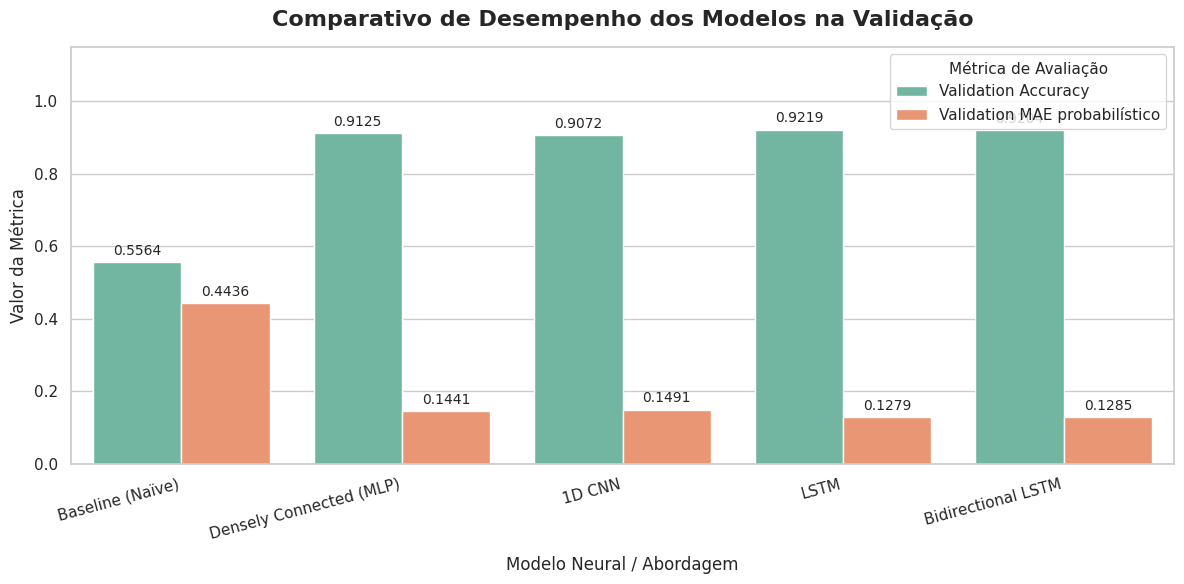

In [61]:
# Importando bibliotecas para a plotagem do gráfico comparativo
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustando o formato do DataFrame para facilitar a plotagem múltipla com o Seaborn
results_melted = pd.melt(
    results,
    id_vars="Modelo",
    value_vars=["Validation Accuracy", "Validation MAE probabilístico"],
    var_name="Métrica",
    value_name="Valor"
)

# Criando a figura
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Plotando gráfico de barras comparando as métricas por modelo lado a lado
ax = sns.barplot(
    data=results_melted,
    x="Modelo",
    y="Valor",
    hue="Métrica",
    palette="Set2"
)

# Adicionando rótulos com os valores exatos sobre as barras para facilitar a leitura
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3, fontsize=10)

# Customização estética do gráfico
plt.title('Comparativo de Desempenho dos Modelos na Validação', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Modelo Neural / Abordagem', fontsize=12, labelpad=10)
plt.ylabel('Valor da Métrica', fontsize=12)
plt.ylim(0, 1.15)  # Margem extra para caber os rótulos no topo
plt.xticks(rotation=15, ha='right', fontsize=11)
plt.legend(title="Métrica de Avaliação", loc="upper right", fontsize=11, title_fontsize=11)

plt.tight_layout()
plt.show()

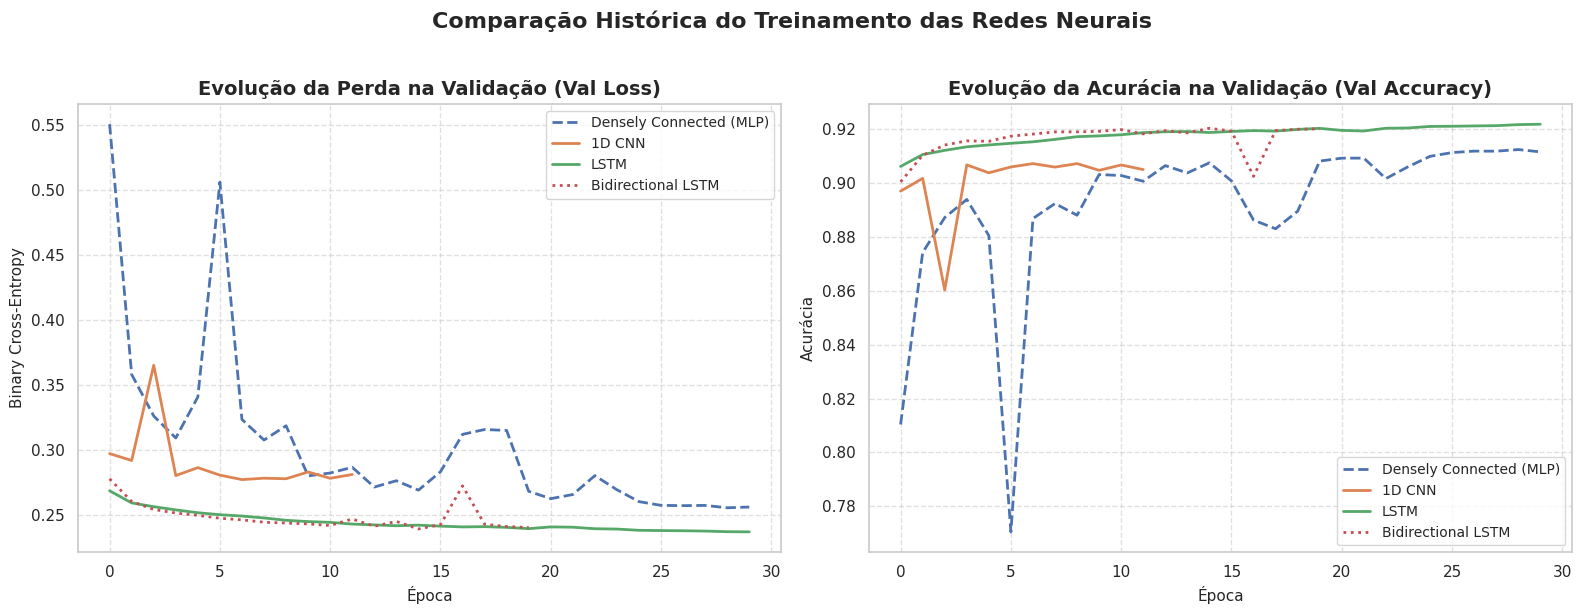

In [62]:
import matplotlib.pyplot as plt

# Criando a figura com dois subplots (Perda e Acurácia de Validação)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de Evolução da Perda de Validação (Validation Loss)
axes[0].plot(history.history['val_loss'], label='Densely Connected (MLP)', color='#4c72b0', linewidth=2, linestyle='--')
axes[0].plot(history_cnn.history['val_loss'], label='1D CNN', color='#dd8452', linewidth=2)
axes[0].plot(history_rnn.history['val_loss'], label='LSTM', color='#55a868', linewidth=2)
axes[0].plot(history_bilstm.history['val_loss'], label='Bidirectional LSTM', color='#c44e52', linewidth=2, linestyle=':')

axes[0].set_title('Evolução da Perda na Validação (Val Loss)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Época', fontsize=11)
axes[0].set_ylabel('Binary Cross-Entropy', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=10)

# 2. Gráfico de Evolução da Acurácia de Validação (Validation Accuracy)
axes[1].plot(history.history['val_accuracy'], label='Densely Connected (MLP)', color='#4c72b0', linewidth=2, linestyle='--')
axes[1].plot(history_cnn.history['val_accuracy'], label='1D CNN', color='#dd8452', linewidth=2)
axes[1].plot(history_rnn.history['val_accuracy'], label='LSTM', color='#55a868', linewidth=2)
axes[1].plot(history_bilstm.history['val_accuracy'], label='Bidirectional LSTM', color='#c44e52', linewidth=2, linestyle=':')

axes[1].set_title('Evolução da Acurácia na Validação (Val Accuracy)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Época', fontsize=11)
axes[1].set_ylabel('Acurácia', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=10)

plt.suptitle('Comparação Histórica do Treinamento das Redes Neurais', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Análise dos Resultados e Conclusões

A partir da consolidação dos resultados obtidos na validação, podemos tirar insights valiosos sobre o comportamento de diferentes arquiteturas aplicadas aos dados de satisfação dos passageiros:

1. **Salto de Qualidade em Relação ao Baseline:**
   O modelo ingênuo (*Baseline Naïve*), que se limitava a replicar a classe majoritária, obteve apenas **55,64%** de acurácia com um erro médio probabilístico (*MAE*) expressivo de **0,4436**. Qualquer uma das técnicas de redes neurais reduziu significativamente o erro e elevou a precisão das previsões para a casa dos 90%, provando que os atributos selecionados carregam forte poder preditivo.

2. **A Supremacia das Redes Recorrentes (LSTM):**
   As arquiteturas baseadas em **LSTM** e **LSTM Bidirecional** apresentaram as melhores marcas do projeto, liderando com **92,19%** e **92,04%** de acurácia, respectivamente. Esses modelos também registraram o menor erro médio absoluto (~**0,1279**). Embora as variáveis não representem uma série temporal clássica no sentido estrito, a capacidade das LSTMs de mapear e memorizar relações de dependência sequencial entre os atributos após o pré-processamento provou ser extremamente eficaz para capturar nuances sutis na experiência do usuário.

3. **Rede Densa vs. Redes Convolucionais:**
   A rede densa tradicional (**MLP**) entregou um resultado robusto de **91,25%** de acurácia com excelente eficiência de tempo de execução. Por outro lado, a **1D CNN**, embora tenha superado o baseline com folga (**90,72%**), ficou ligeiramente abaixo da MLP e das LSTMs. Isso sugere que, para este conjunto de dados estruturado, a busca por padrões estritamente locais de vizinhança feita pelas convoluções não se traduz em vantagem clara frente às conexões globais da rede densa ou à memória das recorrentes.

### Considerações Finais

Este experimento demonstra que a escolha da arquitetura tem impacto direto não apenas nas métricas gerais, mas também no trade-off entre custo computacional e ganho de performance. Para um cenário de produção em que cada fração de percentual na precisão é crítica, as redes **LSTM** destacam-se como a melhor escolha técnica para este problema.

Como próximos passos para potenciais melhorias, sugere-se a exploração de técnicas de sintonia de hiperparâmetros (*Hyperparameter Tuning*) nas camadas da LSTM e a criação de novas variáveis combinadas (*Feature Engineering*) com base nos fatores que mais se correlacionam com a insatisfação dos clientes.